# Задача 4.10
# Длина случайного отрезка в круге

## Условие и необходимое уточнение модели
В единичном круге выбирают случайный отрезок. Найти вероятность длины меньше 1. Слово «случайный» само по себе не задаёт распределение отрезков. Ответ из листка соответствует модели: **оба конца независимо и равномерно выбираются внутри диска**. Решаем эту модель. Если выбирать концы на окружности, получится другая задача; это поясняется ниже.

## Теория с нуля и решение вручную
### 1. Равномерность по площади
Круг радиуса 1 имеет площадь $\pi$. Для равномерной точки вероятность попасть в круг радиуса $r$ равна отношению площадей $r^2$. Поэтому радиус нельзя выбирать равномерно: нужно $R=\sqrt U$, где $U\sim U(0,1)$, а угол независимо $\Theta=2\pi V$:
$$X=\sqrt U\cos(2\pi V),\qquad Y=\sqrt U\sin(2\pi V).$$
Длина отрезка между точками — $D=\sqrt{(X_1-X_2)^2+(Y_1-Y_2)^2}$.

### 2. Плотность разности двух точек
Зафиксируем вектор разности $z$ длины $d$. Первый конец может лежать в пересечении двух единичных дисков со сдвигом $z$. Плотность вектора разности равна площади этого пересечения, делённой на $\pi^2$. Площадь линзы при $0\le d\le2$:
$$L(d)=2\arccos(d/2)-\frac d2\sqrt{4-d^2}.$$
Два сектора дают первую часть, два треугольника — вторую. При переходе к длине вектора кольцо радиуса $d$ и толщины $dd$ имеет площадь $2\pi d\,dd$. Поэтому
$$f_D(d)=\frac{2d}{\pi}L(d),\qquad P(D<1)=\frac1\pi\int_0^1\left[4d\arccos(d/2)-d^2\sqrt{4-d^2}\right]dd.$$

### 3. Вычисление интеграла вручную
Обозначим $J_1=\int_0^1d\arccos(d/2)\,dd$, $J_2=\int_0^1d^2\sqrt{4-d^2}\,dd$. Интегрирование $J_1$ по частям даёт
$$J_1=\frac\pi6+\frac12\int_0^1\frac{d^2}{\sqrt{4-d^2}}\,dd=\frac\pi3-\frac{\sqrt3}4.$$
В обоих оставшихся интегралах подставляем $d=2\sin t$, где $0\le t\le\pi/6$. Для второго:
$$J_2=\int_0^{\pi/6}16\sin^2t\cos^2t\,dt=\left[2t-\tfrac12\sin4t\right]_0^{\pi/6}=\frac\pi3-\frac{\sqrt3}4.$$
Следовательно,
$$P(D<1)=\frac{4J_1-J_2}{\pi}=1-\frac{3\sqrt3}{4\pi}\approx0.58650333.$$

### 4. Почему модель нужно называть
Если оба конца равномерны на **окружности**, меньший угол между ними равномерен на $[0,\pi]$. Длина хорды $2\sin(\theta/2)<1$ при $\theta<\pi/3$, вероятность $1/3$. Если равномерно выбирать расстояние центра до прямой хорды на $[0,1]$, получится $1-\sqrt3/2$. Разные ответы здесь отражают разные опыты.

### 5. Переход к коду
Дважды независимо используем формулу равномерной точки по площади. Проверяем квадрат расстояния меньше 1, чтобы не вычислять лишний квадратный корень. В этой задаче `numpy.cos`, `numpy.sin`, `numpy.sqrt` применяют соответствующие элементарные функции ко всем точкам.

### Как связаны теория и эксперимент

Один опыт — одно полное выполнение условия задачи. Повторяем его независимо $N$ раз. Индикатор $I_k(A)$ равен 1, если событие произошло в опыте $k$, и 0 иначе. Тогда
$$N_A=\sum_{k=1}^{N}I_k(A),\qquad \widehat p_N(A)=\frac{N_A}{N}.$$
По закону больших чисел частота приближается к вероятности при росте числа опытов. Она может колебаться и временно удаляться от ответа: монотонное приближение не обещается. Вероятность — характеристика модели, частота — результат конкретного эксперимента.

Для условной вероятности оставляем только опыты, в которых произошло условие $B$:
$$P(A\mid B)=\frac{P(A\cap B)}{P(B)},\qquad \widehat p(A\mid B)=\frac{N_{A\cap B}}{N_B}.$$
Знаменатель здесь $N_B$, а не общее $N$. Если $N_B=0$, оценка пока не определена.

Приближённая стандартная ошибка частоты равна $\sqrt{\widehat p(1-\widehat p)/m}$, где $m=N$ для обычной вероятности и $m=N_B$ для условной. При достаточно большом числе успехов и неудач ориентировочный 95-процентный интервал имеет вид $\widehat p\pm1.96\sqrt{\widehat p(1-\widehat p)/m}$. Это приближение, а не гарантия для каждого запуска. Для редкого события важен именно ожидаемый счётчик $NP(A)$.

### Что делают библиотеки и общие строки кода

`numpy` хранит результаты опытов в массивах, генерирует случайные числа и считает суммы. Булев массив содержит `True` или `False`; при подсчёте это соответственно 1 и 0. `&` означает «и», `|` — «или», `~` — «не»; каждое сравнение берём в скобки. `axis=1` означает действие внутри строки, то есть внутри одного опыта. Векторные операции повторяют одну и ту же понятную формулу сразу для всех опытов.

`matplotlib.pyplot` рисует график накопленной частоты. Стандартные модули `math` и `fractions` дают элементарные функции, число сочетаний `comb` и точные дроби `Fraction`. Они не выбирают метод решения за нас. В коде используются только эти библиотеки; `scipy` не требуется.

`rng = np.random.default_rng(2026)` создаёт генератор с фиксированным начальным состоянием: повторный запуск даёт тот же эксперимент. Это нужно для воспроизводимости. `rng.random(N)` даёт $N$ независимых равномерных чисел от 0 до 1, а `rng.uniform(a,b,N)` — от $a$ до $b$. Концы непрерывных интервалов имеют вероятность ноль.

Общая функция `report` буквально реализует формулы выше: `np.cumsum` последовательно накапливает единицы, после чего мы делим число успехов на число допустимых опытов. Пунктир — теоретическое значение, если оно известно. На графике показана часть точек для читаемости; в расчёт входят **все** опыты. Интервал выводится только как ориентир точности моделирования.

Два независимых равномерных конца внутри диска: успехов 88290, знаменатель 150000
  частота = 0.58860000; ориентир 95%: [0.58610969; 0.59109031]
  теория = 0.58650333; разность = +0.00209667


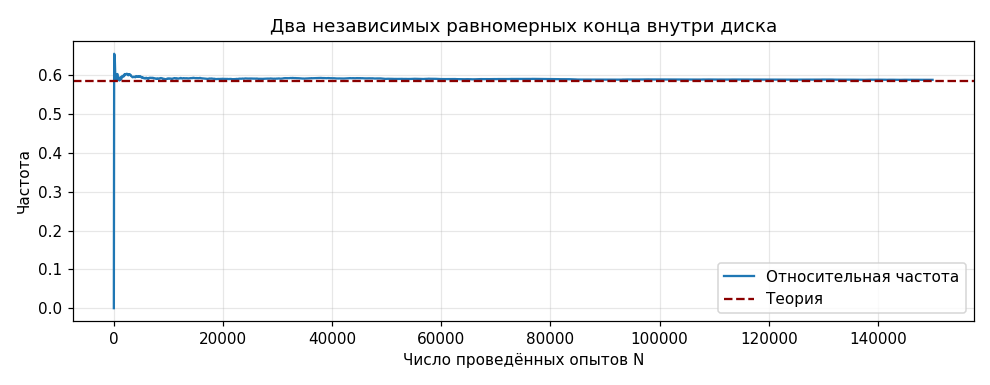

In [1]:
import math
from fractions import Fraction
import numpy as np
import matplotlib.pyplot as plt

# Начальное состояние генератора фиксируем для повторяемого результата.
rng = np.random.default_rng(2026)

def report(event, name, exact=None, condition=None):
    """Частота события, а при condition — условная частота из теории."""
    event = np.asarray(event, dtype=bool)
    if condition is None:
        condition = np.ones(len(event), dtype=bool)
    # В условном случае считаем успех только вместе с выполнением условия.
    successes = np.cumsum(event & condition)
    eligible = np.cumsum(condition)
    frequency = np.full(len(event), np.nan)
    np.divide(successes, eligible, out=frequency, where=(eligible > 0))
    estimate = frequency[-1]
    m = int(eligible[-1])
    error = math.sqrt(estimate * (1 - estimate) / m) if m else float('nan')
    print(f'{name}: успехов {successes[-1]}, знаменатель {m}')
    print(f'  частота = {estimate:.8f}; ориентир 95%: '
          f'[{max(0, estimate - 1.96 * error):.8f}; '
          f'{min(1, estimate + 1.96 * error):.8f}]')
    if exact is not None:
        print(f'  теория = {float(exact):.8f}; разность = {estimate-float(exact):+.8f}')
    # Накопленные суммы рассчитаны по всем опытам; прореживаем лишь рисунок.
    indices = np.unique(np.linspace(0, len(event)-1, min(2500, len(event))).astype(int))
    plt.figure(figsize=(9, 3.5))
    plt.plot(indices+1, frequency[indices], label='Относительная частота')
    if exact is not None:
        plt.axhline(float(exact), color='darkred', linestyle='--', label='Теория')
    plt.xlabel('Число проведённых опытов N')
    plt.ylabel('Частота')
    plt.title(name)
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    return estimate

N = 150_000
def point_in_disk(size):
    # Теория 1: квадратный корень обеспечивает равномерность по площади.
    radius = np.sqrt(rng.random(size))
    angle = 2*math.pi*rng.random(size)
    return radius*np.cos(angle), radius*np.sin(angle)
x1, y1 = point_in_disk(N)
x2, y2 = point_in_disk(N)
A = (x1-x2)**2+(y1-y2)**2 < 1
report(A, 'Два независимых равномерных конца внутри диска', 1-3*math.sqrt(3)/(4*math.pi))
